In [9]:
import os
print("Current Working Directory:", os.getcwd())

Current Working Directory: /Users/charliewang/Documents/GitHub/urban-eureka


In [10]:
from pynwb import NWBHDF5IO
from pynwb import read_nwb
import numpy as np

# Path to downloaded file
filepath = '/Users/charliewang/Documents/GitHub/urban-eureka/data/sub-JenkinsC/sub-JenkinsC_ses-20151001T150307_behavior+ecephys.nwb'

# 'r' mode means Read-only (safe)


io = NWBHDF5IO(filepath, mode='r', load_namespaces=False)
nwbfile = io.read()

#nwb2widget(nwbfile)

#print(nwbfile)
units_table = nwbfile.units
print("///////////////////")
print(units_table)
neuron_0_spikes = nwbfile.units['spike_times'][0]
print(f"Neuron 0 fired {len(neuron_0_spikes)} times.")
print("\nFirst 10 spike timestamps (in seconds):")
print(neuron_0_spikes[:10])
print("///////////////////")
num_neurons = len(nwbfile.units)
print(f"Total neurons (units) recorded: {num_neurons}")
print("///////////////////")

print("///////////////////")



behavior_data = nwbfile.processing['behavior']
cursor_data = behavior_data.data_interfaces['Position'].spatial_series['Cursor']

cursor_pos = cursor_data.data[:]
cursor_times = cursor_data.timestamps[:]
print(cursor_data)
#print(behavior_data.data_interfaces['Position'])
intervals = np.diff(cursor_times)
print("First 5 intervals (in seconds):")
print(intervals[:5])


///////////////////
units pynwb.misc.Units at 0x4684424656
Fields:
  colnames: ['spike_times' 'obs_intervals' 'electrodes' 'electrode_group']
  columns: (
    spike_times_index <class 'hdmf.common.table.VectorIndex'>,
    spike_times <class 'hdmf.common.table.VectorData'>,
    obs_intervals_index <class 'hdmf.common.table.VectorIndex'>,
    obs_intervals <class 'hdmf.common.table.VectorData'>,
    electrodes_index <class 'hdmf.common.table.VectorIndex'>,
    electrodes <class 'hdmf.common.table.DynamicTableRegion'>,
    electrode_group <class 'hdmf.common.table.VectorData'>
  )
  description: Autogenerated by NWBFile
  id: id <class 'hdmf.common.table.ElementIdentifiers'>
  waveform_unit: volts

Neuron 0 fired 55436 times.

First 10 spike timestamps (in seconds):
[0.003 0.006 0.008 0.011 0.015 0.022 0.025 0.037 0.04  0.046]
///////////////////
Total neurons (units) recorded: 192
///////////////////
///////////////////
Cursor pynwb.behavior.SpatialSeries at 0x4679851520
Fields:
  commen

In [11]:
import numpy as np
from scipy.interpolate import interp1d
from scipy.ndimage import gaussian_filter1d

# Define our master time step (50 milliseconds)
bin_size = 0.05 

# Find the very first and very last recorded cursor timestamps
t_start = cursor_times[0]
t_end = cursor_times[-1]

# Create the time edges for our bins
time_bin_edges = np.arange(t_start, t_end, bin_size)

# Machine learning models expect rows to be Time and columns to be Features.
num_bins = len(time_bin_edges) - 1
num_neurons = len(nwbfile.units)

print(f"Creating a matrix of {num_bins} time bins by {num_neurons} neurons.")

# Initialize an empty matrix of zeros (Time x Neurons)
X = np.zeros((num_bins, num_neurons))

for i in range(num_neurons):
    # Grab the raw spike timestamps for this specific neuron
    spikes = nwbfile.units['spike_times'][i]
    
    # np.histogram automatically drops the spikes into the correct time bins
    # It returns the counts, which we assign to the i-th column of X
    binned_spikes, _ = np.histogram(spikes, bins=time_bin_edges)
    X[:, i] = binned_spikes

print(f"X matrix shape: {X.shape}")

# Calculate the exact center time of each bin
bin_centers = time_bin_edges[:-1] + (bin_size / 2)

# Create an interpolation function based on the raw, 4ms cursor data
interpolator = interp1d(cursor_times, cursor_pos, axis=0)

# Feed our new 50ms bin centers into the interpolator
Y_position = interpolator(bin_centers)

print(f"Y_position matrix shape: {Y_position.shape}")

# np.diff calculates the change in X and Y between each row
# We divide by bin_size to get Velocity (distance over time)
velocity = np.diff(Y_position, axis=0) / bin_size

# np.diff makes the array 1 row shorter, so we pad the first row with zeros 
# to ensure it perfectly matches the length of the X matrix
Y_velocity = np.vstack((np.zeros((1, 2)), velocity))

print(f"Y_velocity matrix shape: {Y_velocity.shape}")


#Gaussian filtering
# 1. Define the width of the Gaussian bell curve (Standard Deviation)
# 50ms to 100ms is the standard smoothing window for motor cortex decoding.
sigma_seconds = 0.05  

# 2. Convert that physical time into "number of bins"
# Since our bin_size is 0.05s, sigma_bins will equal 1.0
sigma_bins = sigma_seconds / bin_size  

# 3. Apply the filter along the time axis (axis=0)
# This smooths the data vertically down each neuron's column
X_smoothed = gaussian_filter1d(X, sigma=sigma_bins, axis=0)

# 4. Convert from "Spikes per Bin" to "Hertz (Spikes per Second)"
# If a bin had 2 spikes, and the bin is 0.05s, the rate is 2 / 0.05 = 40 Hz.
X_firing_rate = X_smoothed / bin_size

print(f"X_firing_rate shape: {X_firing_rate.shape}")
print(f"Max firing rate found: {np.max(X_firing_rate):.1f} Hz")

Creating a matrix of 94718 time bins by 192 neurons.
X matrix shape: (94718, 192)
Y_position matrix shape: (94718, 2)
Y_velocity matrix shape: (94718, 2)
X_firing_rate shape: (94718, 192)
Max firing rate found: 387.6 Hz


In [19]:
# A 100ms delay is standard for arm kinematics
delay_seconds = 0.10

# Calculate how many bins that equals (0.10 / 0.05 = 2 bins)
lag_bins = int(delay_seconds / bin_size)

# Shift the matrices
# We drop the last few bins of X, and the first few bins of Y
X_shifted = X_firing_rate[:-lag_bins]
Y_shifted = Y_velocity[lag_bins:]

print(f"Original X shape: {X_firing_rate.shape}")
print(f"Shifted X shape:  {X_shifted.shape}")
print(f"Shifted Y shape:  {Y_shifted.shape}")

# 1. Check the raw maximums to prove the glitch exists
print("Max absolute X velocity:", np.max(np.abs(Y_shifted[:, 0])))
print("Max absolute Y velocity:", np.max(np.abs(Y_shifted[:, 1])))

# 2. Find the 99.9th percentile (the maximum biological speed)
# This ignores the top 0.1% of insane tracking glitches
y_threshold = np.percentile(np.abs(Y_shifted[:, 1]), 99.9)
x_threshold = np.percentile(np.abs(Y_shifted[:, 0]), 99.9)

# 3. Clip the matrix
# Anything moving faster than the threshold is forced down to the threshold
Y_shifted_clean = np.copy(Y_shifted)
Y_shifted_clean[:, 0] = np.clip(Y_shifted[:, 0], -x_threshold, x_threshold)
Y_shifted_clean[:, 1] = np.clip(Y_shifted[:, 1], -y_threshold, y_threshold)

print(f"\nClipped Y max velocity to biological limit: {y_threshold:.1f}")

Original X shape: (94718, 192)
Shifted X shape:  (94716, 192)
Shifted Y shape:  (94716, 2)
Max absolute X velocity: 2535.6
Max absolute Y velocity: 28794.8

Clipped Y max velocity to biological limit: 715.3


In [20]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import Ridge



# Split the data, explicitly setting shuffle=False
X_train, X_test, Y_train, Y_test = train_test_split(
    X_shifted, 
    Y_shifted_clean, 
    test_size=0.2, 
    shuffle=False
)



scaler = StandardScaler()
# Fit on train, transform train
X_train_scaled = scaler.fit_transform(X_train)
# ONLY transform test (do not fit)
X_test_scaled = scaler.transform(X_test)

print(f"Training on {X_train_scaled.shape[0]} time bins.")
print(f"Testing on {X_test_scaled.shape[0]} time bins.")


alphas_to_test = np.logspace(1, 8, 8)

# Initialize RidgeCV to automatically find the best alpha
ridge_decoder = RidgeCV(alphas=alphas_to_test)

# Train the model (it will test all 6 alphas and keep the best one)
ridge_decoder.fit(X_train_scaled, Y_train)

print(f"The solver selected an optimal alpha of: {ridge_decoder.alpha_}")
print(f"Learned weight matrix shape: {ridge_decoder.coef_.shape}")

# The resulting weight matrix shape will be (2 dimensions x N neurons)
print(f"Learned weight matrix shape: {ridge_decoder.coef_.shape}")

Training on 75772 time bins.
Testing on 18944 time bins.
The solver selected an optimal alpha of: 100.0
Learned weight matrix shape: (2, 192)
Learned weight matrix shape: (2, 192)


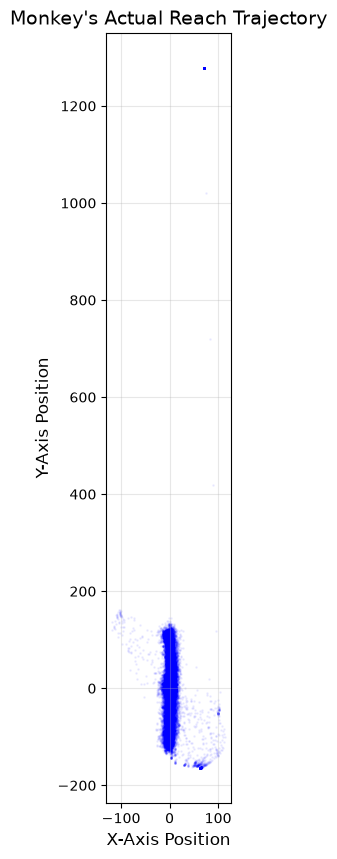

In [21]:
import matplotlib.pyplot as plt

# 1. Extract the X and Y coordinates from your position matrix
# Column 0 is X-axis, Column 1 is Y-axis
x_coords = Y_position[:, 0]
y_coords = Y_position[:, 1]

# 2. Set up a large, square canvas
plt.figure(figsize=(10, 10))

# 3. Create a high-density scatter plot
plt.scatter(x_coords, y_coords, s=1, alpha=0.05, color='blue')

# 4. CRITICAL STEP: Lock the aspect ratio
# This forces the X and Y axes to have the exact same physical scale on your monitor.
# Without this, matplotlib will auto-stretch the graph to fit a rectangle, 
# which would hide the exact behavioral bias we are trying to find!
plt.gca().set_aspect('equal', adjustable='box')

# 5. Add labels and a grid
plt.title("Monkey's Actual Reach Trajectory", fontsize=14)
plt.xlabel("X-Axis Position", fontsize=12)
plt.ylabel("Y-Axis Position", fontsize=12)
plt.grid(True, alpha=0.3)

plt.show()

In [22]:
from sklearn.metrics import r2_score


# Predict the kinematics for the held-out test set
Y_pred = ridge_decoder.predict(X_test_scaled)

# Calculate the R-squared score
# An R^2 of 1.0 is perfect prediction; 0.0 is predicting the mean
r2_x = r2_score(Y_test[:, 0], Y_pred[:, 0])
r2_y = r2_score(Y_test[:, 1], Y_pred[:, 1])

print(f"X-Axis Velocity R^2: {r2_x:.3f}")
print(f"Y-Axis Velocity R^2: {r2_y:.3f}")

X-Axis Velocity R^2: 0.171
Y-Axis Velocity R^2: 0.523
